
# 3D Ising Model: Phase Transitions in Three Dimensions

## 1. Introduction

The Ising model is a fundamental model in statistical mechanics used to study magnetic ordering and phase transitions.

In this project, I extend the two-dimensional Ising model to a three-dimensional cubic lattice. Each spin can take one of two values: +1 (up) or -1 (down).

Unlike the 2D model, each spin in the 3D cubic lattice interacts with six nearest neighbors.

## 2. Objective

The goal of this agentic session is to develop a working prototype of the 3D Ising model using the Metropolis Monte Carlo algorithm.

The main objectives are:

1. Construct a 3D cubic lattice of spins.
2. Implement the Metropolis algorithm with periodic boundary conditions.
3. Simulate the system at low and high temperatures.
4. Visualize the 3D spin configurations.
5. Observe how magnetic ordering changes with temperature.

This prototype will serve as the foundation for a larger portfolio project investigating phase transitions in three dimensions.

## 3. Physical Model

The Hamiltonian of the 3D Ising model is

$$
H = -J \sum_{\langle i,j \rangle} s_i s_j
$$

where:

- $J$ is the interaction strength.
- $s_i = \pm 1$ represents the spin at lattice site $i$.
- $\langle i,j \rangle$ denotes nearest-neighbor pairs.

For this simulation, we assume:

- Ferromagnetic interactions: $J = 1$
- Boltzmann constant: $k_B = 1$
- Zero external magnetic field
- Periodic boundary conditions

The Metropolis algorithm will be used to update the spins and investigate their behavior at different temperatures.


Lattice shape: (10, 10, 10)
Total number of spins: 1000
Initial magnetization: 0.018


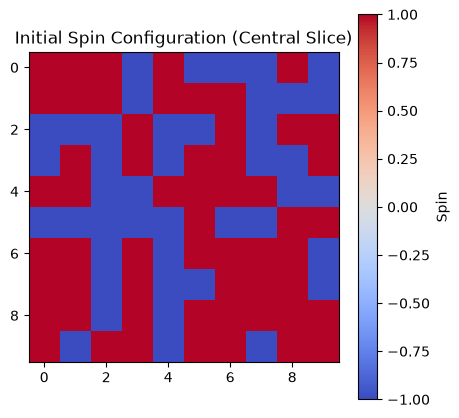

In [1]:

import numpy as np
import matplotlib.pyplot as plt

L = 10
J = 1.0

rng = np.random.default_rng(42)

spins = rng.choice([-1, 1], size=(L, L, L))

print("Lattice shape:", spins.shape)
print("Total number of spins:", spins.size)
print("Initial magnetization:", np.mean(spins))

plt.figure(figsize=(5, 5))
plt.imshow(spins[:, :, L // 2], cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Initial Spin Configuration (Central Slice)")
plt.colorbar(label="Spin")
plt.show()



## 4. Metropolis Monte Carlo Algorithm

The Metropolis algorithm is used to simulate the evolution of the spin system at a given temperature.

For each attempted spin flip, the change in energy is calculated as

$$
\Delta E = 2J s_i \sum_{j \in NN(i)} s_j
$$

where $NN(i)$ represents the six nearest neighbors of spin $i$.

A proposed spin flip is accepted if:

- $\Delta E \leq 0$, or
- A random number is smaller than $\exp(-\Delta E/T)$.

Periodic boundary conditions are applied along all three dimensions.


In [2]:

def metropolis_sweep(spins, T, rng):
    L = spins.shape[0]

    for _ in range(L**3):
        i, j, k = rng.integers(0, L, size=3)

        s = spins[i, j, k]

        neighbors = (spins[(i+1)%L, j, k] + spins[(i-1)%L, j, k] + spins[i, (j+1)%L, k] + spins[i, (j-1)%L, k] + spins[i, j, (k+1)%L] + spins[i, j, (k-1)%L])

        delta_E = 2 * J * s * neighbors

        if delta_E <= 0 or rng.random() < np.exp(-delta_E / T):
            spins[i, j, k] = -s

    return spins

print("Metropolis algorithm is ready!")


Metropolis algorithm is ready!



## 5. Simulation at Different Temperatures

To investigate the effect of temperature on magnetic ordering, I simulate the 3D Ising model at two temperatures:

- Low temperature: T = 2.0
- High temperature: T = 7.0

The approximate critical temperature of the 3D Ising model is T_c = 4.51 (for J = k_B = 1).

For each temperature, the simulation starts from a random spin configuration and runs for 100 Monte Carlo sweeps.

The magnetization per spin is recorded after each sweep to observe how the system evolves.


In [3]:

temperatures = [2.0, 7.0]
results = {}
n_sweeps = 100

for T in temperatures:
    spins = rng.choice([-1, 1], size=(L, L, L))
    magnetization = []

    for step in range(n_sweeps):
        metropolis_sweep(spins, T, rng)
        magnetization.append(np.mean(spins))

    results[T] = {"spins": spins.copy(), "magnetization": magnetization}

    print(f"T = {T}: Final magnetization = {np.mean(spins):.3f}")


T = 2.0: Final magnetization = 0.998
T = 7.0: Final magnetization = 0.050


### Analysis

The simulation produced the following final magnetization values:

- At T = 2.0: M = 0.998
- At T = 7.0: M = 0.050

At low temperature, the magnetization is close to 1, indicating that almost all spins are aligned.

At high temperature, the magnetization is close to 0, indicating a disordering state in which positive and negative spins approximately cancel each other.


## 6. Visualization of 3D Spin Configurations

To visualize magnetic ordering in three dimensions, I plot the spins in the cubic lattice at low and high temperatures.

The visualization allows us to compare the ordered and disordered magnetic states.


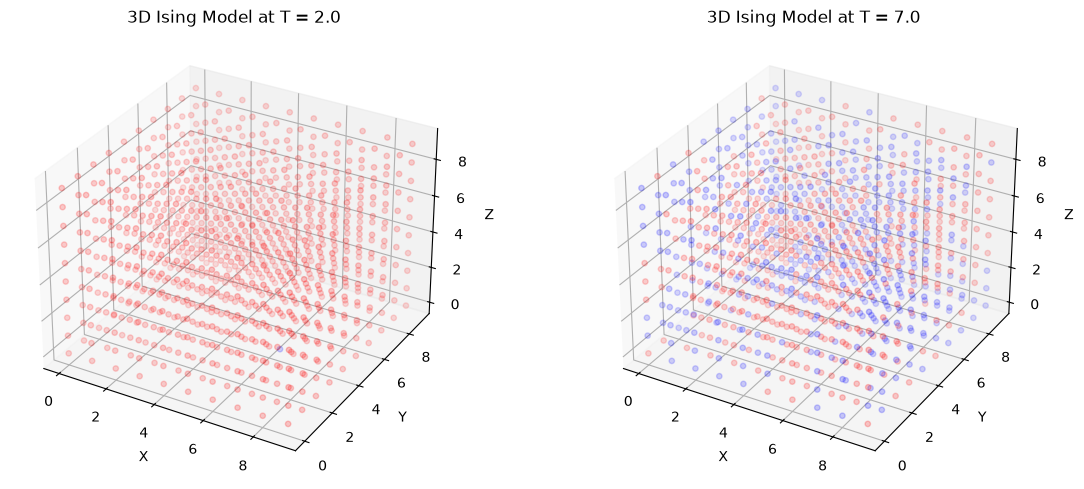

In [4]:

fig = plt.figure(figsize=(12, 5))

for index, T in enumerate(temperatures):
    spins = results[T]["spins"]

    ax = fig.add_subplot(1, 2, index + 1, projection="3d")

    x, y, z = np.indices(spins.shape)

    colors = np.where(spins.flatten() == 1, "red", "blue")

    ax.scatter(x.flatten(), y.flatten(), z.flatten(), c=colors, s=15, alpha=0.5)

    ax.set_title(f"3D Ising Model at T = {T}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

plt.tight_layout()
plt.show()



### Analysis of 3D Spin Configurations

The 3D visualizations show a clear difference in spin configurations at low and high temperatures.

**At T = 2.0 (Low Temperature):**
- Almost all spins are aligned in the same direction (red points).
- The system exhibits strong ferromagnetic ordering.
- Thermal fluctuations are relatively weak, allowing neighboring spins to align.

**At T = 7.0 (High Temperature):**
- Positive (red) and negative (blue) spins are distributed throughout the lattice.
- The system exhibits a disordered magnetic state.
- Stronger thermal fluctuations prevent long-range magnetic ordering.

**Physical Interpretation:**

The results are consistent with the expected behavior of the 3D Ising model. Below the critical temperature (T_c ≈ 4.51), the system develops spontaneous magnetization, while above the critical temperature, the magnetization is close to zero.

These visualizations demonstrate the difference between ordered and disordered magnetic states in three dimensions.


## 7. Magnetization Evolution

To investigate how magnetic ordering develops during the simulation, I plot the magnetization per spin as a function of Monte Carlo sweeps.

The magnetization is defined as

$$
m = \frac{1}{N}\sum_{i=1}^{N}s_i
$$

where $N = L^3$ is the total number of spins.

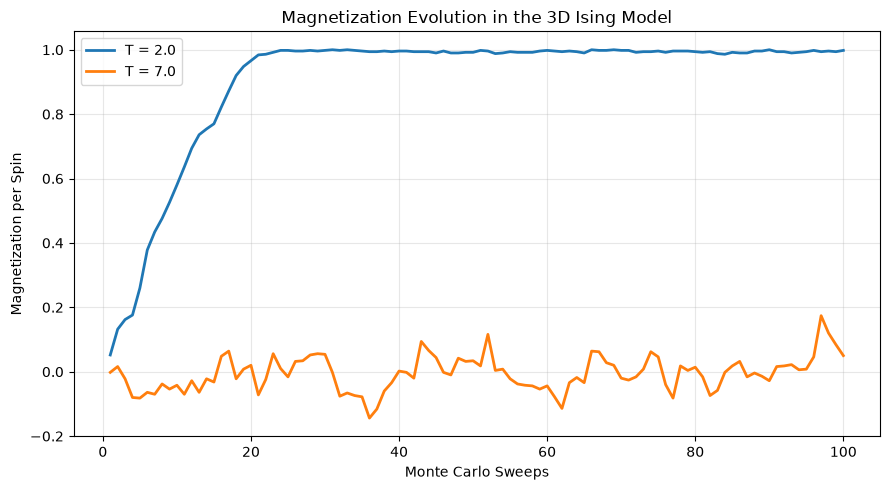

In [5]:

plt.figure(figsize=(9, 5))

for T in temperatures:
    plt.plot(range(1, n_sweeps + 1), results[T]["magnetization"], label=f"T = {T}", linewidth=2)

plt.xlabel("Monte Carlo Sweeps")
plt.ylabel("Magnetization per Spin")
plt.title("Magnetization Evolution in the 3D Ising Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Analysis

The magnetization evolution shows two distinct behaviors at low and high temperatures.

**At T = 2.0:**
- The magnetization increases rapidly from approximately 0.05 to nearly 1.0 within the first 25 Monte Carlo steps.
- After reaching this value, the magnetization remains nearly constant, indicating a strongly ordered ferromagnetic state.
- This demonstrates how the initially disordered system develops magnetic order at low temperature.

**At T = 7.0:**
- The magnetization fluctuates around zero throughout the simulation.
- No persistent magnetic ordering develops.
- This behavior is consistent with a disordered paramagnetic state, where thermal fluctuations dominate.




## 8. Spin-Spin Correlation Function at Criticality

At the critical temperature, the 3D Ising model exhibits long-range correlations characterized by a power-law decay.

The two-point spin correlation function is defined as

$$
G(r) = \langle s(0)s(r)\rangle
$$

At criticality, it is expected to behave as

$$
G(r) \sim \frac{1}{r^{2\Delta_\sigma}}
$$

where $\Delta_\sigma$ is the scaling dimension of the spin operator.

The theoretical value is approximately

$$
\Delta_\sigma \approx 0.51815
$$

### Objective

The goal is to estimate the scaling dimension numerically by:

1. Simulating the 3D Ising model near its critical temperature.
2. Computing the spin-spin correlation function.
3. Plotting the correlation function on a log-log scale.
4. Fitting a power law to estimate $\Delta_\sigma$.
5. Comparing the numerical estimate with the theoretical value.


In [6]:

L_crit = 32
T_crit = 4.5115
J_crit = 1.0

rng_crit = np.random.default_rng(123)
spins_crit = rng_crit.choice(
    [-1, 1], size=(L_crit, L_crit, L_crit)
).astype(np.int8)

x, y, z = np.indices(spins_crit.shape)
parity = (x + y + z) % 2
masks = [parity == 0, parity == 1]

def critical_sweep(spins, T):
    for mask in masks:
        neighbors = sum(
            np.roll(spins, shift, axis=axis).astype(np.int16)
            for axis in range(3)
            for shift in (-1, 1)
        )

        dE = 2 * J_crit * spins * neighbors

        accept = (dE <= 0) | (
            rng_crit.random(spins.shape) < np.exp(
                -np.maximum(dE, 0) / T
            )
        )

        spins[mask & accept] *= -1

for _ in range(600):
    critical_sweep(spins_crit, T_crit)

distances = np.arange(1, L_crit // 4 + 1)
correlations = np.zeros(len(distances))

n_measurements = 100

for _ in range(n_measurements):
    for _ in range(10):
        critical_sweep(spins_crit, T_crit)

    for index, r in enumerate(distances):
        axis_corr = [
            np.mean(
                spins_crit *
                np.roll(spins_crit, -int(r), axis=axis)
            )
            for axis in range(3)
        ]

        correlations[index] += np.mean(axis_corr)

correlations /= n_measurements

print("Distances:", distances)
print("Correlations:", np.round(correlations, 5))
print("Critical simulation completed!")


Distances: [1 2 3 4 5 6 7 8]
Correlations: [0.34277 0.17954 0.12418 0.09954 0.08652 0.07857 0.07297 0.06931]
Critical simulation completed!


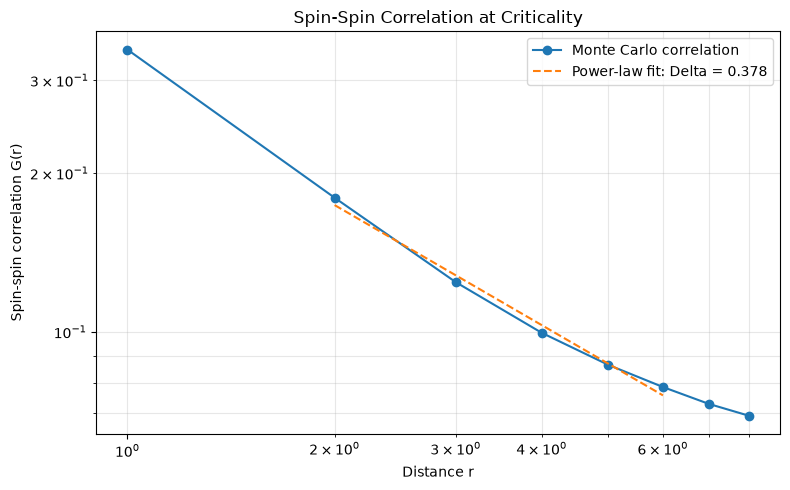

Fitted slope: -0.7562
Estimated Delta_sigma: 0.3781
Theoretical Delta_sigma: 0.5181


In [7]:
fit_mask = ((distances >= 2) & (distances <= 6) & (correlations > 0))

r_fit = distances[fit_mask]
G_fit = correlations[fit_mask]

slope, intercept = np.polyfit(np.log(r_fit), np.log(G_fit), 1)

delta_sigma = -slope / 2
theoretical_delta = 0.5181489

plt.figure(figsize=(8, 5))

plt.loglog(distances, correlations, "o-", label="Monte Carlo correlation")

plt.loglog(r_fit, np.exp(intercept) * r_fit**slope, "--", label=f"Power-law fit: Delta = {delta_sigma:.3f}")

plt.xlabel("Distance r")
plt.ylabel("Spin-spin correlation G(r)")
plt.title("Spin-Spin Correlation at Criticality")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Fitted slope: {slope:.4f}")
print(f"Estimated Delta_sigma: {delta_sigma:.4f}")
print(f"Theoretical Delta_sigma: {theoretical_delta:.4f}")



### Analysis

The spin-spin correlation function was calculated at the critical temperature T = 4.5115 using a 32 × 32 × 32 cubic lattice.

The correlation function decreases with increasing distance, consistent with the expected critical behavior.

A power-law fit over distances r = 2 to 6 gives:

- Fitted slope: -0.7562
- Estimated scaling dimension: 0.3781
- Theoretical scaling dimension: 0.5181
- Relative error: approximately 27%

The numerical estimate is lower than the theoretical value. Possible sources of discrepancy include finite-size effects, insufficient sampling, limited fitting range, and contributions from the finite-system magnetization.

Although the fitted curve describes the selected data points reasonably well, the current simulation is not sufficient for an accurate determination of the critical exponent.

### Future Improvements

To obtain a more reliable estimate, I plan to:

1. Increase the number of Monte Carlo measurements.
2. Investigate the connected spin-spin correlation function.
3. Compare results for different lattice sizes.
4. Examine finite-size effects and fitting-range sensitivity.

These improvements will help assess whether the numerical results approach the theoretical scaling dimension.
